# Flight Booking Decision Assistant — focused practice

**Target:** understand and demonstrate the project in approximately 10 minutes, and submit by **Wednesday, October 14, 2026, 9 PM MST**. This is the only practice Notebook. Read `PRACTICE_GUIDE.md` first.

The project investigates whether a time-and-price Q-learning policy lowers simulated purchase cost versus simple rules. The three validation questions are: **Does it save money? How uncertain is the saving estimate? Is the learned policy good, and does the program follow the rules?**

This Notebook contains all four practice parts. No waiting for chat answers is required. Predict first, try a small TODO, read the hint, run its check, then inspect the separate solution. Supplied solution outputs are **agent verification, not your personal completion**.

**Important:** unfinished TODOs intentionally raise `NotImplementedError` when called. Run cells individually; do not use Run All until your TODOs are complete. Select **Python (CS664 Flight Booking)**. Setup is intact. The main Notebook and `results/` are read-only references here; practice exports go only to `practice_results/`.

## P0. Setup — run these cells first
Load the existing trained Q-table and actual official evidence. This practice does not retrain, regenerate test prices, implement statistical functions, solve the whole MDP, or write official results.

In [1]:
# 1A — imports and official settings
from pathlib import Path
import csv
import json
import sys
import numpy as np
from IPython.display import display, Markdown

PRICES = np.array([120, 180, 240, 300, 360], dtype=int)
BOOK, WAIT = 0, 1
ACTION_NAMES = {BOOK: "BOOK", WAIT: "WAIT"}
TRAIN_EPISODES, TEST_TRAJECTORIES = 50_000, 10_000
ALPHA, GAMMA = 0.1, 1.0
TRAIN_SEED, TEST_SEED = 66401, 66402
OFFICIAL_THRESHOLD = 180
assert TRAIN_SEED != TEST_SEED
print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("Training/test seeds:", TRAIN_SEED, TEST_SEED)

Python: /Users/sheungwanwong/Documents/bu.met.mssd/fall1.2026/metcs664/CS664_Project_Wong_Sheung_Wan/.venv/bin/python
NumPy: 2.5.4
Training/test seeds: 66401 66402


In [2]:
# P0-DATA — load saved evidence safely
from IPython.display import Image

ROOT = Path.cwd()
assert (ROOT / 'results/run_summary.json').exists(), 'Start Jupyter from the project folder'
OFFICIAL = ROOT / 'results'
PRACTICE_OUTPUT = ROOT / 'practice_results'
PRACTICE_OUTPUT.mkdir(exist_ok=True)

def read_csv(name):
    with (OFFICIAL / name).open(newline='') as file:
        return list(csv.DictReader(file))

summary = json.loads((OFFICIAL / 'run_summary.json').read_text())
Q = np.load(OFFICIAL / 'q_values.npy', allow_pickle=False)
official_paths = np.load(OFFICIAL / 'test_trajectories.npy', allow_pickle=False)
Q.setflags(write=False)
official_paths.setflags(write=False)
PRICE_INDEX = {int(price): i for i, price in enumerate(PRICES)}
mean_rows = read_csv('mean_cost_comparison.csv')
ci_rows = read_csv('paired_savings_95ci.csv')
mdp_rows = read_csv('exact_mdp_comparison.csv')
state_rows = read_csv('exact_state_values.csv')
verification_rows = read_csv('verification_results.csv')
assert Q.shape == (7, 5, 2) and official_paths.shape == (10_000, 7)
assert summary['training_seed'] == TRAIN_SEED and summary['test_seed'] == TEST_SEED
print('Loaded official Q-table, 10,000 price paths, tables, and verification evidence.')

Loaded official Q-table, 10,000 price paths, tables, and verification evidence.


In [3]:
# P0-FORMAT — provided display and practice export helpers
def show_rows(rows, columns=None):
    columns = columns or list(rows[0])
    lines = ['| ' + ' | '.join(columns) + ' |',
             '| ' + ' | '.join(['---'] * len(columns)) + ' |']
    for row in rows:
        lines.append('| ' + ' | '.join(str(row[column]) for column in columns) + ' |')
    display(Markdown('\n'.join(lines)))

def save_practice_csv(name, rows):
    with (PRACTICE_OUTPUT / name).open('w', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]), lineterminator='\n')
        writer.writeheader()
        writer.writerows(rows)

solution_checks_run = []
print('Practice outputs:', PRACTICE_OUTPUT)

Practice outputs: /Users/sheungwanwong/Documents/bu.met.mssd/fall1.2026/metcs664/CS664_Project_Wong_Sheung_Wan/practice_results


## Part 1 — Environment
**Purpose:** explain what the agent observes and what an action changes. State is `(time remaining, current fare)`. There are seven opportunities, 6 to 0, and five prices. BOOK receives negative fare and terminates; WAIT receives 0 and advances one day. Attempted boundary moves stay at $120 or $360. At time 0, booking is mandatory.

The probability regime uses time **before** WAIT: at 6–3, +60/0/−60 probabilities are 0.3/0.3/0.4; at 2–1, they are 0.6/0.2/0.2. These are hypothetical assumptions.

**Predict:** (A) BOOK at `(6, 240)`; (B) WAIT at `(3, 120)` when the sampled move is −$60. For each, state next state, reward, done, and effective action. What happens if WAIT is requested at time 0?

The following transition function and reset code are supplied. Controlled states/moves below are teaching fixtures, not changes to the actual random environment.

In [4]:
# 2A — one price transition
def next_price(time_remaining, price, rng):
    if time_remaining not in range(1, 7) or price not in PRICES:
        raise ValueError("WAIT requires time 1–6 and a valid price")
    probabilities = (0.3, 0.3, 0.4) if time_remaining >= 3 else (0.6, 0.2, 0.2)
    change = int(rng.choice([60, 0, -60], p=probabilities))
    return int(np.clip(price + change, PRICES[0], PRICES[-1]))

In [5]:
# P1-BASE — provided episode initialization
class FlightBookingEnv:
    def __init__(self, rng):
        self.rng = rng
        self.state = None
        self.done = True

    def reset(self):
        self.state = (6, int(self.rng.choice(PRICES)))
        self.done = False
        return self.state

### P1 exercise — one deadline rule
Complete only `effective_action` below. The existing exercise cell is preserved, including any saved attempt.

**Hint:** check whether time is zero; choose the required action in that case and preserve the requested action otherwise. After editing, rerun P1-TODO, then P1-CHECK.

In [ ]:
# P1-TODO — complete one line; leave the surrounding code intact.
class PracticeBookingEnv(FlightBookingEnv):
    def step(self, action):
        if self.done:
            raise RuntimeError("Reset before acting; a purchase ends the episode")
        if action not in (BOOK, WAIT):
            raise ValueError("Action must be BOOK or WAIT")
        time_remaining, price = self.state

        # TODO P1: enforce deadline booking; otherwise use the requested action.
        effective_action = ...

        if effective_action is Ellipsis:
            raise NotImplementedError("Complete TODO P1 before running the check")
        if effective_action == BOOK:
            self.done = True
            return None, -price, True, effective_action
        self.state = (time_remaining - 1, next_price(time_remaining, price, self.rng))
        return self.state, 0, False, effective_action

In [ ]:
# P1-CHECK — run after completing and rerunning P1-TODO.
class DecreaseOnlyRNG:
    def choice(self, values, p=None):
        return 120 if p is None else -60

def check_topic_1():
    env = PracticeBookingEnv(DecreaseOnlyRNG())
    env.reset()
    env.state = (1, 120)
    state, reward, done, action = env.step(WAIT)
    assert state == (0, 120), "WAIT must advance time and respect the lower bound"
    assert reward == 0 and not done and action == WAIT
    terminal, reward, done, action = env.step(WAIT)
    assert terminal is None and reward == -120 and done and action == BOOK
    try:
        env.step(BOOK)
    except RuntimeError:
        pass
    else:
        raise AssertionError("Actions after purchase must be rejected")
    env.reset()
    env.state = (6, 240)
    terminal, reward, done, action = env.step(BOOK)
    assert terminal is None and reward == -240 and done and action == BOOK
    env.reset()
    env.state = (0, 180)
    assert env.step(WAIT) == (None, -180, True, BOOK)
    print("PASS P1: boundary, WAIT reward/time, immediate BOOK, deadline BOOK, termination.")

check_topic_1()

### P1 solution and model answers — inspect after trying
The missing line is `effective_action = BOOK if time_remaining == 0 else action`.

(A) BOOK at `(6, 240)` returns `(None, -240, True, BOOK)`. (B) The downward boundary WAIT returns `((2, 120), 0, False, WAIT)`. A requested WAIT at `(0, 180)` becomes BOOK and returns `(None, -180, True, BOOK)`. No next state exists after purchase; a further step raises `RuntimeError` until reset.

**Explain aloud:** why is −120 better than −300, and why does a $120 boundary stay not terminate a WAIT? Answer: higher reward means lower cost; reaching a cheap price alone is not a purchase.

In [6]:
# P1-SOLUTION — separate reference class
# P1-SOLUTION — separate supplied reference, not your TODO answer
class SolutionBookingEnv(FlightBookingEnv):
    def step(self, action):
        if self.done:
            raise RuntimeError("Reset before acting; a purchase ends the episode")
        if action not in (BOOK, WAIT):
            raise ValueError("Action must be BOOK or WAIT")
        time_remaining, price = self.state

        # Enforce deadline booking; otherwise preserve the requested action.
        effective_action = BOOK if time_remaining == 0 else action

        if effective_action is Ellipsis:
            raise NotImplementedError("Complete TODO P1 before running the check")
        if effective_action == BOOK:
            self.done = True
            return None, -price, True, effective_action
        self.state = (time_remaining - 1, next_price(time_remaining, price, self.rng))
        return self.state, 0, False, effective_action

In [7]:
# P1-TRACE — supplied solution: show actual controlled BOOK/WAIT examples
class FixedMoveRNG:
    def __init__(self, move):
        self.move = move
    def choice(self, values, p=None):
        return 240 if p is None else self.move

transition_examples = []
for state, action, move in [((6, 240), BOOK, 0), ((3, 120), WAIT, -60)]:
    env = SolutionBookingEnv(FixedMoveRNG(move))
    env.reset()
    env.state = state
    following, reward, done, effective = env.step(action)
    transition_examples.append({'state': str(state), 'action': ACTION_NAMES[action],
        'next_state': str(following), 'reward': reward, 'done': done,
        'effective_action': ACTION_NAMES[effective]})
assert next_price(1, 360, FixedMoveRNG(60)) == 360
assert transition_examples[0]['next_state'] == 'None' and transition_examples[0]['reward'] == -240
assert transition_examples[1]['next_state'] == '(2, 120)' and transition_examples[1]['reward'] == 0
show_rows(transition_examples)
save_practice_csv('environment_examples.csv', transition_examples)
solution_checks_run.append('P1: upper boundary and supplied BOOK/WAIT traces')

| state | action | next_state | reward | done | effective_action |
| --- | --- | --- | --- | --- | --- |
| (6, 240) | BOOK | None | -240 | True | BOOK |
| (3, 120) | WAIT | (2, 120) | 0 | False | WAIT |

## Part 2 — Q-learning
**Purpose:** learn an action's eventual purchase cost from observed experience. `updated = old + alpha × (target − old)`. For a purchase, `target = reward`; there is no future value. For WAIT, `target = reward + gamma × best legal next-state Q-value`. Negative Q-values are rewards, so greedy selection chooses the larger value.

**Calculate before coding:** use the two actual logged updates displayed below. The terminal update has no next state. The WAIT update's best next-state value **at that training moment** was −30; it is not necessarily the final Q-table value. Fill two lines per function; no training loop is required.

In [8]:
# P2-DATA — actual observed updates from training
terminal_example = summary['first_update']
wait_example = summary['observed_wait_update']
print('Actual terminal update:', terminal_example)
print('Actual nonterminal update:', wait_example)
print('Calculate target and updated value yourself before reading the solutions.')

Actual terminal update: {'episode': 1, 'state': [6, 120], 'action': 'BOOK', 'old': 0.0, 'reward': -120, 'target': -120.0, 'learning_rate': 0.1, 'updated': -12.0, 'terminal': True}
Actual nonterminal update: {'episode': 376, 'state': [1, 240], 'action': 'WAIT', 'old': 0.0, 'reward': 0, 'target': -30.0, 'learning_rate': 0.1, 'updated': -3.0, 'terminal': False}
Calculate target and updated value yourself before reading the solutions.


In [ ]:
# P2-TODO — terminal and nonterminal updates
def terminal_update_practice(old, reward, alpha, future_value=None):
    target = ...  # TODO: terminal target, even if a future value is supplied.
    updated = ...  # TODO: old + alpha times the correction.
    if target is Ellipsis or updated is Ellipsis:
        raise NotImplementedError('Complete both terminal-update TODOs')
    return target, updated

def wait_update_practice(old, reward, alpha, gamma, future_value):
    target = ...  # TODO: reward plus discounted best legal future value.
    updated = ...  # TODO: update the old value toward the target.
    if target is Ellipsis or updated is Ellipsis:
        raise NotImplementedError('Complete both WAIT-update TODOs')
    return target, updated

**Hint:** the terminal target ignores `future_value`. The nonterminal target uses the future value once; alpha changes the Q-value, not the environment reward. Gamma is 1 in this project.

In [ ]:
# P2-CHECK — check your two update functions
assert np.allclose(terminal_update_practice(0, -120, 0.1, 999), (-120, -12))
assert np.allclose(terminal_update_practice(-180, -240, 0.1, 999), (-240, -186))
assert np.allclose(wait_update_practice(0, 0, 0.1, 1.0, -30), (-30, -3))
assert np.allclose(wait_update_practice(-200, 0, 0.1, 1.0, -180), (-180, -198))
print('PASS: terminal reward-only and nonterminal bootstrap calculations.')

### P2 action-selection exercise
**Predict:** at `(6, 180)`, epsilon = 0.05, draw = 0.03, random action = WAIT, greedy action = BOOK. What action is taken during training? What happens with epsilon = 0 during evaluation?

**Hint:** a draw below epsilon uses the supplied random action. Otherwise use the greedy action. The deadline overrides both. Exploration can also randomly choose BOOK; it does not always mean WAIT.

In [ ]:
# P2-EPS-TODO — one epsilon-greedy action line
def training_action_practice(state, epsilon, draw, random_action, greedy_action):
    if state[0] == 0:
        return BOOK
    action = ...  # TODO: use draw < epsilon to choose exploration or exploitation.
    if action is Ellipsis:
        raise NotImplementedError('Complete the epsilon-greedy TODO')
    return action

In [ ]:
# P2-EPS-CHECK — training, evaluation, and deadline cases
assert training_action_practice((6, 180), 0.05, 0.03, WAIT, BOOK) == WAIT
assert training_action_practice((6, 180), 0.05, 0.8, WAIT, BOOK) == BOOK
assert training_action_practice((6, 180), 0, 0, WAIT, BOOK) == BOOK
assert training_action_practice((6, 180), 0.05, 0.05, WAIT, BOOK) == BOOK
assert training_action_practice((0, 180), 1, 0, WAIT, WAIT) == BOOK
print('PASS: exploration, greedy evaluation, strict inequality, deadline BOOK.')

### P2 solutions and model answers — separate from your functions
Actual terminal update: old 0, target −120, alpha 0.1, updated −12. Actual WAIT update: old 0, reward 0, gamma 1, future −30, target −30, updated −3. Additional check cases are controlled arithmetic examples, not logged training events.

With draw 0.03 below epsilon 0.05, choose WAIT during training; epsilon 0 chooses greedy BOOK. Training decays epsilon from 1 to 0.05 over 40,000 episodes and holds 0.05 through episode 50,000. Official evaluation uses deterministic greedy actions and **never changes Q**. Deadline WAIT is illegal, including when calculating the next-state maximum.

In [9]:
# P2-SOLUTION — supplied arithmetic and epsilon functions
def terminal_update_solution(old, reward, alpha, future_value=None):
    target = reward
    return target, old + alpha * (target - old)

def wait_update_solution(old, reward, alpha, gamma, future_value):
    target = reward + gamma * future_value
    return target, old + alpha * (target - old)

def training_action_solution(state, epsilon, draw, random_action, greedy_action):
    if state[0] == 0:
        return BOOK
    return random_action if draw < epsilon else greedy_action

print('Terminal target/update:', terminal_update_solution(0, -120, 0.1, 999))
print('WAIT target/update:', wait_update_solution(0, 0, 0.1, 1.0, -30))
print('Training action:', ACTION_NAMES[training_action_solution((6, 180), .05, .03, WAIT, BOOK)])

Terminal target/update: (-120, -12.0)
WAIT target/update: (-30.0, -3.0)
Training action: WAIT


## Part 3 — Fair comparison
**Purpose:** explain a fair comparison and calculate paired savings. This teaching sample uses actual test trajectory indices **0, 1, and 4**, selected to illustrate different outcomes, not randomly to estimate population performance. It is **not** the official 10,000-trajectory experiment; do not draw significance conclusions from it.

All four policies get the same trajectories. They receive only current state; the evaluator keeps the full path privately and stops at purchase. Training seed 66401 and test seed 66402 are separate. Different seeds separate random streams; shared test paths preserve within-trip pairing and reduce noise in comparisons.

In [10]:
# P3-POLICIES — provided four rules using only current state
def greedy_action(state):
    t, price = state
    return BOOK if t == 0 else int(np.argmax(Q[t, PRICE_INDEX[price]]))

def threshold_policy(threshold):
    def policy(state):
        t, price = state
        return BOOK if t == 0 or price <= threshold else WAIT
    return policy

TEACHING_POLICIES = {
    'Immediate booking': lambda state: BOOK,
    'Minimum-price rule ($120)': threshold_policy(120),
    'Fixed-threshold rule ($180)': threshold_policy(180),
    'Q-learning (greedy)': greedy_action,
}
TEACHING_IDS = [0, 1, 4]

In [11]:
# P3-EVALUATOR — supplied stop-at-purchase runner
def run_teaching_path(path, policy):
    trace = []
    for day in range(7):
        state = (6 - day, int(path[day]))
        requested = policy(state)  # Only two current-state values are passed.
        action = BOOK if state[0] == 0 else requested
        assert action in (BOOK, WAIT)
        trace.append({'state': state, 'action': ACTION_NAMES[action]})
        if action == BOOK:
            return state[1], trace
    raise AssertionError('Mandatory deadline booking must end the path')

q_snapshot = Q.copy()
teaching_rows = []
teaching_costs = {name: [] for name in TEACHING_POLICIES}
for index in TEACHING_IDS:
    for name, policy in TEACHING_POLICIES.items():
        cost, trace = run_teaching_path(official_paths[index], policy)
        teaching_costs[name].append(cost)
        teaching_rows.append({'trajectory': index, 'strategy': name,
            'observed decisions': '; '.join(f"{s['state']}:{s['action']}" for s in trace),
            'purchase_cost': cost})
show_rows(teaching_rows)
save_practice_csv('teaching_purchase_decisions.csv', teaching_rows)
assert np.array_equal(Q, q_snapshot)

| trajectory | strategy | observed decisions | purchase_cost |
| --- | --- | --- | --- |
| 0 | Immediate booking | (6, 180):BOOK | 180 |
| 0 | Minimum-price rule ($120) | (6, 180):WAIT; (5, 180):WAIT; (4, 240):WAIT; (3, 240):WAIT; (2, 180):WAIT; (1, 120):BOOK | 120 |
| 0 | Fixed-threshold rule ($180) | (6, 180):BOOK | 180 |
| 0 | Q-learning (greedy) | (6, 180):BOOK | 180 |
| 1 | Immediate booking | (6, 360):BOOK | 360 |
| 1 | Minimum-price rule ($120) | (6, 360):WAIT; (5, 300):WAIT; (4, 360):WAIT; (3, 360):WAIT; (2, 360):WAIT; (1, 360):WAIT; (0, 360):BOOK | 360 |
| 1 | Fixed-threshold rule ($180) | (6, 360):WAIT; (5, 300):WAIT; (4, 360):WAIT; (3, 360):WAIT; (2, 360):WAIT; (1, 360):WAIT; (0, 360):BOOK | 360 |
| 1 | Q-learning (greedy) | (6, 360):WAIT; (5, 300):WAIT; (4, 360):WAIT; (3, 360):WAIT; (2, 360):WAIT; (1, 360):WAIT; (0, 360):BOOK | 360 |
| 4 | Immediate booking | (6, 300):BOOK | 300 |
| 4 | Minimum-price rule ($120) | (6, 300):WAIT; (5, 240):WAIT; (4, 240):WAIT; (3, 240):WAIT; (2, 240):WAIT; (1, 180):WAIT; (0, 240):BOOK | 240 |
| 4 | Fixed-threshold rule ($180) | (6, 300):WAIT; (5, 240):WAIT; (4, 240):WAIT; (3, 240):WAIT; (2, 240):WAIT; (1, 180):BOOK | 180 |
| 4 | Q-learning (greedy) | (6, 300):WAIT; (5, 240):WAIT; (4, 240):BOOK | 240 |

### P3 exercise — one saving and a three-trip mean
For trajectory **4**, calculate $180-rule cost minus Q-learning cost. Then calculate the mean of that paired saving across trajectories **0, 1, 4**. A negative saving means Q-learning was more expensive.

**Hint:** subtract within each matched trip first, then average those differences. Do not mix baseline costs from one trajectory with Q-learning costs from another.

In [ ]:
# P3-TODO — two small arithmetic expressions
def paired_saving_practice(baseline_cost, learned_cost):
    saving = ...  # TODO: baseline minus Q-learning cost.
    if saving is Ellipsis:
        raise NotImplementedError('Complete the paired-saving TODO')
    return saving

def mean_saving_practice(savings):
    mean = ...  # TODO: mean of the matched savings.
    if mean is Ellipsis:
        raise NotImplementedError('Complete the small-sample mean TODO')
    return mean

In [ ]:
# P3-CHECK — the actual teaching sample
baseline = teaching_costs['Fixed-threshold rule ($180)']
learned = teaching_costs['Q-learning (greedy)']
savings = [paired_saving_practice(b, q) for b, q in zip(baseline, learned)]
assert savings == [0, 0, -60]
assert np.isclose(mean_saving_practice(savings), -20)
print('PASS: trajectory 4 saving is -$60; teaching-sample mean is -$20.')

### P3 solutions and model answers
Trajectory 4 costs $180 under the fixed rule and $240 under Q-learning: saving = −$60. Across the three trips, savings are 0, 0, −60; mean = −$20. This does not contradict the official +$4.884 mean on 10,000 trips: a small, deliberately selected teaching sample can look different.

**Question:** can a policy use day 7's price to decide at day 1? **Answer:** no; the policy's function receives only `(time remaining, current price)`. Pre-generation is the evaluator's way to share random paths, not permission to peek. **Question:** why no exploration at test time? **Answer:** compare the learned policy's actual greedy decisions, without random training actions or further learning.

In [12]:
# P3-SOLUTION — supplied arithmetic and comparison checks
def paired_saving_solution(baseline_cost, learned_cost):
    return baseline_cost - learned_cost

def mean_saving_solution(savings):
    return float(np.mean(savings))

cost_evidence = read_csv('paired_purchase_costs.csv')
for row in teaching_rows:
    assert row['purchase_cost'] == int(cost_evidence[row['trajectory']][row['strategy']])
for policy in TEACHING_POLICIES.values():
    path = official_paths[4]
    cost, trace = run_teaching_path(path, policy)
    changed = path.copy()
    changed[len(trace):] = 120
    assert run_teaching_path(changed, policy) == (cost, trace)
assert np.array_equal(Q, q_snapshot)
print('PASS: all 12 teaching purchases match official paired costs; no future-suffix influence; Q unchanged.')
solution_checks_run.append('P3: actual teaching costs, pairing, future isolation, frozen Q')

PASS: all 12 teaching purchases match official paired costs; no future-suffix influence; Q unchanged.


## Part 4 — Validation and presentation
**Purpose:** connect code and evidence to the three validation questions. You do not need to explain every row of raw data. Explain the experiment, the three summary conclusions, one trace, and the limits.

### Validation 1: does it save money?
Read the actual four-strategy mean table below. Which strategy has the lowest sampled mean? What does the $4.884 saving versus the $180 rule mean?

### Validation 2: how uncertain is the estimated mean saving?
Read the three paired 95% intervals. Does the interval versus the $180 rule include zero? Does it say that 95% of individual trips save between those endpoints? Could another training seed learn a different policy?

In [13]:
# P4-TABLES — actual official means and intervals (read only)
show_rows(mean_rows, ['strategy', 'trajectories', 'mean_purchase_cost'])
show_rows(ci_rows, ['baseline', 'mean_paired_saving', 'ci_95_lower', 'ci_95_upper'])
print('These are official sampled results on 10,000 shared fresh paths; not teaching-sample estimates.')

| strategy | trajectories | mean_purchase_cost |
| --- | --- | --- |
| Immediate booking | 10000 | 239.58 |
| Minimum-price rule ($120) | 10000 | 223.476 |
| Fixed-threshold rule ($180) | 10000 | 219.738 |
| Q-learning (greedy) | 10000 | 214.854 |

| baseline | mean_paired_saving | ci_95_lower | ci_95_upper |
| --- | --- | --- | --- |
| Immediate booking | 24.726 | 23.83794657844081 | 25.614053421559188 |
| Minimum-price rule ($120) | 8.622 | 7.240777367133834 | 10.003222632866166 |
| Fixed-threshold rule ($180) | 4.884 | 4.029366493534513 | 5.738633506465487 |

These are official sampled results on 10,000 shared fresh paths; not teaching-sample estimates.


### Validation 3: did it learn a good policy, and does the code obey the rules?
Use the actual analytical reference below. Explain why the learned policy can beat simple baselines yet remain suboptimal. The optimal solver is a reference; it is not a fifth strategy in the official sampled comparison.

**Small backward-induction exercise:** at time 1 and price $360, only the mandatory deadline remains after WAIT. The late probabilities are +60: 0.6, unchanged: 0.2, −60: 0.2. Price boundaries still apply. At time 0, expected purchase cost equals the current price. Compute WAIT's expected cost, then compare with BOOK at $360. Fill two lines; you are not implementing the complete solver.

In [ ]:
# P4-MDP-TODO — one final-step expectation
def final_step_practice():
    price = 360
    up_price = min(360, price + 60)
    same_price = price
    down_price = max(120, price - 60)
    waiting_cost = ...  # TODO: probability-weighted deadline purchase costs.
    if waiting_cost is Ellipsis:
        raise NotImplementedError('Complete the backward-induction cost TODO')
    action = ...  # TODO: choose the lower-cost action; BOOK wins a tie.
    if action is Ellipsis:
        raise NotImplementedError('Complete the backward-induction action TODO')
    return waiting_cost, action

**Hint:** an attempted rise from $360 stays at $360. Weight all three possible outcomes, including two that end at the same boundary price. This calculation minimizes costs; Q-learning maximizes negative rewards.

In [ ]:
# P4-MDP-CHECK — deadline boundary and cost comparison
waiting_cost, action = final_step_practice()
assert np.isclose(waiting_cost, 348)
assert action == WAIT
print('PASS: final-step WAIT expectation is $348, below BOOK at $360.')

| policy | exact_expected_cost | gap_above_optimal |
| --- | --- | --- |
| Optimal MDP reference | 207.27422399999995 | 0.0 |
| Immediate booking | 240.0 | 32.72577600000005 |
| Minimum-price rule ($120) | 224.172768 | 16.898544000000044 |
| Fixed-threshold rule ($180) | 220.822656 | 13.548432000000048 |
| Q-learning (greedy) | 215.70911999999998 | 8.434896000000037 |

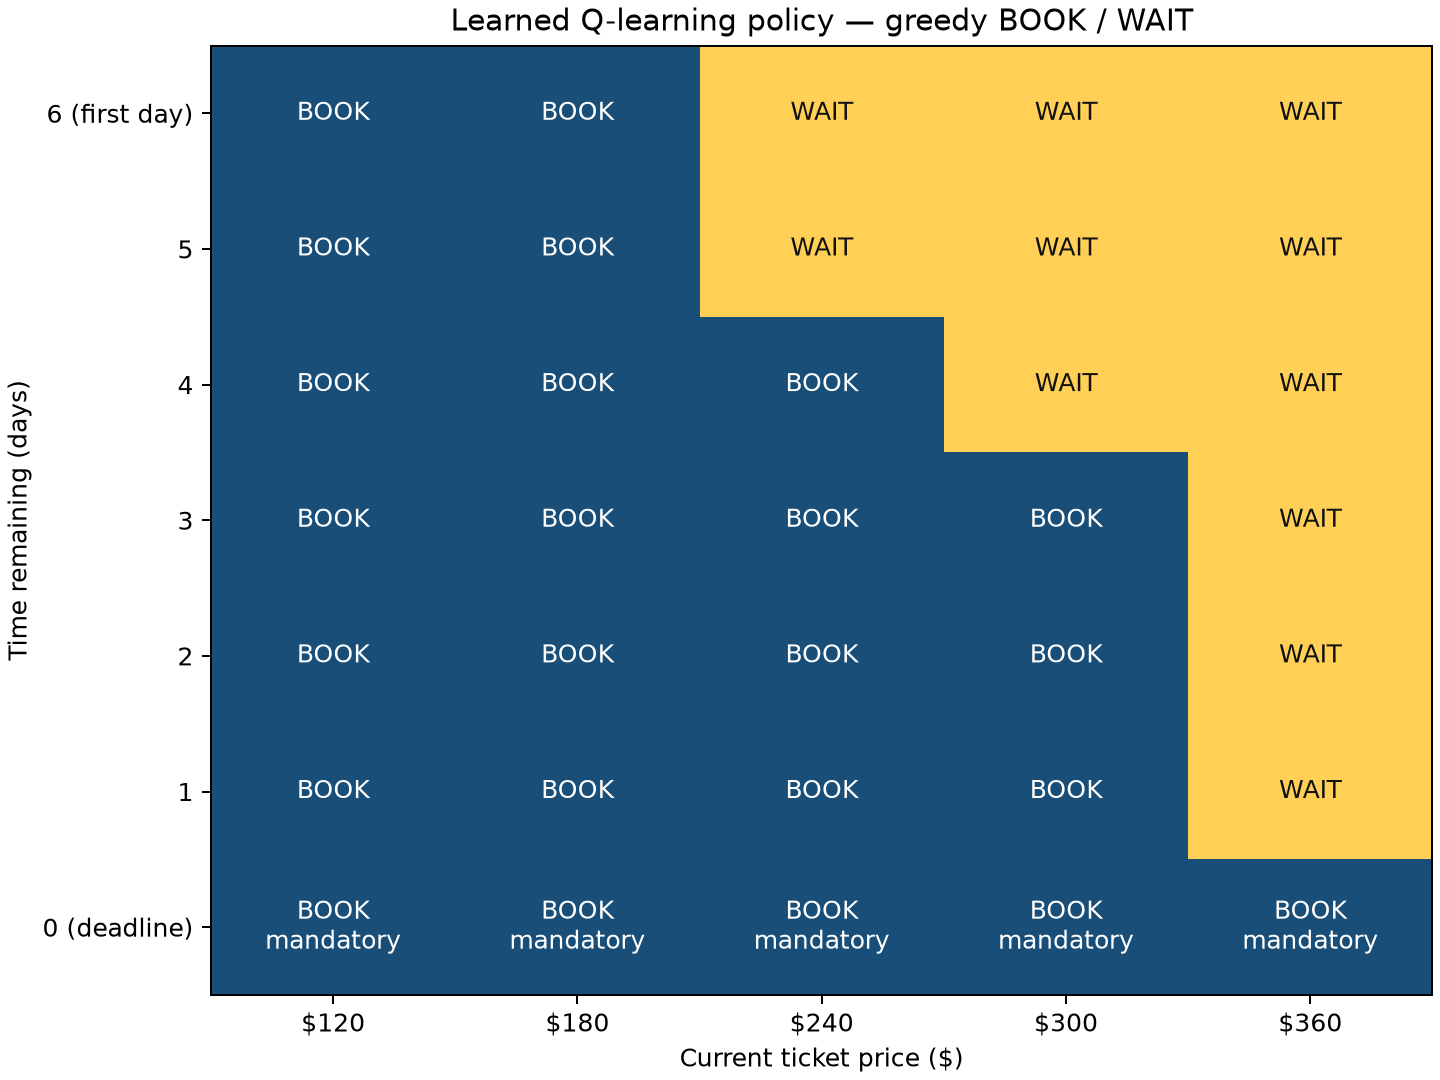

Interpret this state on the heatmap: (6, 240)
Interpret this state on the heatmap: (1, 240)
Interpret this state on the heatmap: (0, 180)
Interpret this state on the heatmap: (6, 180)


| day | time_remaining | price | action | reward | purchase_cost |
| --- | --- | --- | --- | --- | --- |
| 1 | 6 | 360 | WAIT | 0 |  |
| 2 | 5 | 300 | WAIT | 0 |  |
| 3 | 4 | 360 | WAIT | 0 |  |
| 4 | 3 | 360 | WAIT | 0 |  |
| 5 | 2 | 360 | WAIT | 0 |  |
| 6 | 1 | 360 | WAIT | 0 |  |
| 7 | 0 | 360 | BOOK | -360 | 360 |

| check | cases | status | detail |
| --- | --- | --- | --- |
| simulator transitions | 90 | PASS | all time/price/move combinations; probability regimes; both boundaries |
| episode rules | 7 | PASS | all purchase days; BOOK/WAIT rewards; deadline; reject post-purchase action |
| Q-value updates | 2 | PASS | legal next-action bootstrap; terminal reward-only target |
| exact MDP reference | 18225 | PASS | five full latent-path expectations match backward induction; optimal dominates all policies |
| policy actions | 5 | PASS | all deadline prices force BOOK; Q-table unchanged |
| paired intervals | 2 | PASS | zero differences; paired toy sample SD and Student-t critical value |
| future-price isolation | 400 | PASS | future suffix edits cannot change any observed decision; Q-table unchanged |

All displayed checks/results are saved official evidence, not new personal practice.


In [14]:
# P4-REFERENCES — actual MDP, policy heatmap, trace, and checks
show_rows(mdp_rows, ['policy', 'exact_expected_cost', 'gap_above_optimal'])
display(Image(filename=str(OFFICIAL / 'policy_heatmap.png')))
heatmap_states = [(6, 240), (1, 240), (0, 180), (6, 180)]
for state in heatmap_states:
    print('Interpret this state on the heatmap:', state)
show_rows(read_csv('q_learning_trace.csv'),
          ['day', 'time_remaining', 'price', 'action', 'reward', 'purchase_cost'])
show_rows(verification_rows)
print('All displayed checks/results are saved official evidence, not new personal practice.')

### P4 interpretation questions — answer aloud
1. What does the $180-baseline interval establish about mean savings, and what does it not establish about a single trip?
2. Why are the sampled Q-learning cost and analytical learned-policy cost different?
3. Explain the actions at `(6, 240)`, `(1, 240)`, `(0, 180)`, and `(6, 180)`. Is every learned action optimal?
4. What do the boundary/reward/deadline/termination checks establish? What do they fail to establish?
5. Why is the shown $360 purchase compatible with positive average savings?

### P4 solutions and model answers
**Mean and CI:** Q-learning's sampled mean is $214.854, versus $219.738 for the $180 rule. Mean paired saving is $4.884; its individual paired 95% interval is [$4.029366, $5.738634], above zero. The other mean costs are $239.58 (immediate) and $223.476 ($120 rule). This supports a positive mean saving for this fixed policy in this model; it is not a range containing 95% of individual-trip savings. Individual trip differences include zero and negative values.

These are large-sample Student-t intervals for a mean of paired differences. They condition on this one trained policy, do not capture variation across training seeds or model error, and are not simultaneous three-comparison intervals. They are not a 95% probability statement that this fixed mean lies inside this particular computed interval.

**MDP:** full-model optimal expected cost is $207.274224; learned-policy expected cost is $215.709120; learned minus optimal is $8.434896. “Exact” is full finite-horizon expectation to floating-point precision. The sampled $214.854 uses only 10,000 realized trips and differs through sampling. The analytical learned expectation evaluates the final greedy policy; it does not read Q-values as if they were exact costs or retrain the policy.

**Heatmap:** `(6,240)` WAIT; `(1,240)` BOOK; `(0,180)` mandatory BOOK. At `(6,180)`, the learned policy BOOKs while the exact optimal action is WAIT. Thus beating fixed rules does not mean learning the optimum. The single final-step calculation below is only a teaching example; the main Notebook implements the full solver.

**Correctness:** executed checks support the specified transition probabilities, clipping, zero WAIT/negative BOOK rewards, deadline booking, termination, legal Q targets, state-only calls, and frozen evaluation. Full latent-path enumeration independently checks analytical expectations. They do not validate the hypothetical probabilities against real airfare, guarantee convergence, establish performance across seeds, or replace a proof of all possible software behavior.

**Trace:** the illustrated trip waits six times and BOOKs at the deadline for $360. Average savings allow expensive trips; this illustration was selected for readable length, not used to estimate performance.

In [15]:
# P4-MDP-SOLUTION — one backward step, not the whole solver
def final_step_solution():
    price = 360
    up_price, same_price, down_price = 360, 360, 300
    waiting_cost = 0.6 * up_price + 0.2 * same_price + 0.2 * down_price
    action = WAIT if waiting_cost < price else BOOK
    return waiting_cost, action

cost, action = final_step_solution()
print(f'WAIT: 0.6 × 360 + 0.2 × 360 + 0.2 × 300 = ${cost:.0f}; action {ACTION_NAMES[action]}.')
expected_actions = {(6, 240): WAIT, (1, 240): BOOK, (0, 180): BOOK, (6, 180): BOOK}
for state, expected in expected_actions.items():
    assert greedy_action(state) == expected
exact_state = next(row for row in state_rows if row['time_remaining'] == '6' and row['price'] == '180')
assert exact_state['optimal_action'] == 'WAIT' and exact_state['learned_action'] == 'BOOK'
assert np.isclose(summary['exact_mdp']['gap_above_optimal'], 8.434896)
assert all(row['status'] == 'PASS' for row in verification_rows)
assert all(float(row['ci_95_lower']) > 0 for row in ci_rows)
print('PASS: supplied interpretations agree with the actual official evidence.')
solution_checks_run.append('P4: backward step, four heatmap states, exact gap, saved checks, interval signs')

WAIT: 0.6 × 360 + 0.2 × 360 + 0.2 × 300 = $348; action WAIT.
PASS: supplied interpretations agree with the actual official evidence.


## Timed approximately 10-minute presentation checklist
Use the **main Notebook** for the recorded full demo. Practice is preparation, not a submission deliverable. You need not explain all 10,000 rows or implement the MDP/CI code live.

| Time | What to show and explain |
|---|---|
| 0:00–0:45 | Goal: investigate whether current fare plus time remaining helps reduce simulated booking cost versus three simple rules. State the three validation questions. |
| 0:45–2:00 | Environment: seven opportunities, state, hypothetical probabilities, price clipping, rewards, mandatory deadline BOOK, purchase termination. Show one BOOK/WAIT example. |
| 2:00–4:00 | Key Q-learning code: old/target/alpha/updated; terminal target without bootstrap; WAIT with future value; one actual update. |
| 4:00–4:45 | Epsilon-greedy training (1 to 0.05); greedy evaluation (0 exploration); legal deadline action. |
| 4:45–6:00 | Execute the whole main project: Restart Kernel and Run All, or `.venv/bin/python run_notebook.py`. Show actual completed outputs and checks. Explain shared paths, separate seeds, no future access, four strategies. |
| 6:00–7:15 | Validation 1 and 2: four mean costs, one paired saving, $180-rule saving $4.884 and CI about [$4.029,$5.739]; distinguish individual variation from mean uncertainty. |
| 7:15–8:45 | Validation 3: exact optimum $207.274 vs learned expectation $215.709, gap $8.435; heatmap and complete trace; learned policy remains suboptimal. |
| 8:45–10:00 | Limitations and conclusion: hypothetical data, one training seed, no convergence/per-trip guarantee; show RESULTS.md and saved CSV/PNG verification evidence. |

Before recording, rehearse once with a timer and explain the numbers without reading raw rows. Turn the camera on as required by the instructor PDF. The final PDF/Word writeup, project ZIP, and recording are separate submission items. Upload by **October 14, 9 PM MST**, allowing time to confirm uploads. Do not create the ZIP from this practice Notebook.

In [17]:
# P-END — save supplied-solution verification only
verification = {
    'source': 'execution of supplied solutions and evidence displays; not student completion',
    'personal_completion': 'not established; user must attempt and explain exercises',
    'official_results_modified': False,
    'solution_checks_run': solution_checks_run,
}
(PRACTICE_OUTPUT / 'solution_verification.json').write_text(json.dumps(verification, indent=2) + '\n')
print('Saved supplied-solution evidence in practice_results/. Your TODO answers remain separate.')

Saved supplied-solution evidence in practice_results/. Your TODO answers remain separate.
